# Dogri ⇄ Punjabi — IndicTrans2-1B + LoRA, **v3 (translation-memory augmented)**

**Two fully independent adapters (`doi2pan`, `pan2doi`). Nothing is shared between them.**

## What the v2 logs say (why more of the same will not help)

| Observation in v2 | What it means |
|---|---|
| doi2pan val BLEU: ep1 52.47 → ep3 53.89 → ep5 53.87. pan2doi: 45.52 → 47.89 over 6 epochs | ~90 % of the gain is in the first epoch; the optimiser has converged. More epochs/LR/rank will not move it. |
| Checkpoint averaging: +0.06 / −0.12 BLEU. Decoding grid: ±0.05 BLEU | Both are far below noise. Dropped in v3 (as you suggested). |
| v2 vs v1 test: +0.33 / +0.32 BLEU | With 1,158 test sentences the 95 % CI of a BLEU difference is about ±1. So the "wider data" change is **not proven**, and 0.3 steps are not worth chasing. |
| Round-trip ceiling 93–95 BLEU, `<unk>` 0.09 %, BP 0.98–0.99 | Script conversion, tokenizer and output length are **not** the bottleneck (length costs ≤ 1.7 BLEU). |
| Base 45.3 / 38.8 → fine-tuned 53.3 / 46.7; Dogri side is weaker | The remaining errors are **lexical / spelling-convention** errors: the model does not know how *this corpus* renders a phrase, especially in Dogri. |

So the model is not short of optimisation, it is short of **information at inference time**. The corpus looks like a narrow, templated domain (agri-advice sentences), where near-duplicate sentences are common.

## v3 change: fuzzy-match translation memory (retrieval-augmented fine-tuning)

For every source sentence we retrieve the most similar *training* sentence (TF-IDF → re-ranked by word-level edit ratio) and append its **reference translation** to the encoder input:

`<lang tags> source sentence || fm7 || retrieved target (Devanagari)`

(`fm7` = match-quality bucket, so the model learns how much to trust the match.) The adapter learns to copy / minimally edit the retrieved translation. This gives the model exactly the missing information: the corpus' own wording and spelling.

* **Leave-one-out** on training examples (a sentence never retrieves itself); 10 % of training inputs get no match so the model still works without one.
* Memory = **strict** training pairs only. Validation uses a train-only memory; at final test the memory additionally includes the validation pairs (labelled data you really have). The test set is never in any memory.
* Fully independent adapters per direction, one retrieval index per direction.
* Cell 8 **measures first** how many sentences have a usable match. If very few do, TM will not help and the cell says so.
* Final cell reports TM **on vs off** for the same adapter, a paired-bootstrap CI, results by match-quality bucket, and a word-confusion error analysis.

Honest caveat: gains are proportional to how repetitive the data is, and a *random* split (like ours) is friendlier than a held-out shared-task test set. Cell 8 and the bucket table show exactly how much of any gain comes from high-overlap sentences.

Removed vs v2: epoch-checkpoint averaging, decoding grid, base-model re-evaluation (v2 numbers are hard-coded), per-epoch adapter dumps. Epochs 5 / 4 with patience 2 (≈ 4–4.5 h total on one T4).


In [1]:
# =============================================================================
# CELL 1 — INSTALL DEPENDENCIES  (same pins as before)  + CUDA stability settings
# =============================================================================
# ---- FIX: must run before torch touches CUDA (restart the session first!)
import os
USE_SINGLE_GPU = True                      # DataParallel (2xT4) + PEFT + custom collator is the usual cause of
if USE_SINGLE_GPU:                         # "CUDA error: unspecified launch failure" -> train on 1 GPU
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
# os.environ["CUDA_LAUNCH_BLOCKING"] = "1"  # uncomment only to debug (slow)

!pip install -q uv

!uv pip install --system \
    "transformers<4.40.0" \
    "peft<=0.10.0" \
    "accelerate>=0.28.0,<0.30.0" \
    datasets \
    sacrebleu \
    sentencepiece \
    einops \
    pandas \
    numpy \
    scikit-learn \
    tqdm \
    sentence-transformers

!uv pip install --system "git+https://github.com/VarunGumma/IndicTransToolkit.git"

import torch, transformers, peft, sacrebleu
print("PyTorch      :", torch.__version__)
print("Transformers :", transformers.__version__)
print("PEFT         :", peft.__version__)
print("SacreBLEU    :", sacrebleu.__version__)
if torch.cuda.is_available():
    print("GPU          :", torch.cuda.get_device_name(0), "| count:", torch.cuda.device_count())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.9/17.9 MB 88.2 MB/s eta 0:00:00
Using Python 3.13.15 environment at: /usr
Resolved 83 packages in 726ms
Prepared 8 packages in 276ms
Uninstalled 6 packages in 894ms
Installed 8 packages in 45ms
 - accelerate==1.14.0
 + accelerate==0.29.3
 - huggingface-hub==1.29.0
 + huggingface-hub==0.36.2
 - peft==0.20.0
 + peft==0.10.0
 + portalocker==4.4.0
 + sacrebleu==2.6.0
 - sentence-transformers==5.7.0
 + sentence-transformers==3.1.1
 - tokenizers==0.23.1
 + tokenizers==0.15.2
 - transformers==5.16.1
 + transformers==4.39.3
Using Python 3.13.15 environment at: /usr
Resolved 56 packages in 592ms
Prepared 7 packages in 9.83s
Installed 7 packages in 6ms
 + indic-nlp-library-itt==0.1.1
 + indictranstoolkit==1.1.1 (from git+https://github.com/VarunGumma/IndicTransToolkit.git@3efb8418d0721b4ce267c2b3586899d313191357)
 + morfessor==2.0.6
 + sacremoses==0.2.0
 + sphinx-argparse==0.6.1
 + sphinx-rtd-theme==3.1.0
 + sphinxcontrib-jquery==4.1
PyTorch      : 

In [2]:
# =============================================================================
# CELL 2 — GLOBAL CONFIGURATION  (Dogri <-> Punjabi, IndicTrans2-1B, LoRA v3 + translation memory)
# =============================================================================
import os, gc, re, json, glob, shutil, random, time, unicodedata, difflib
from pathlib import Path

import numpy as np
import pandas as pd
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# T4 / P100 have no bf16 -> fp16 there; bf16 only on Ampere+.
_cc_major = torch.cuda.get_device_capability(0)[0] if torch.cuda.is_available() else 0
MODEL_DTYPE = torch.bfloat16 if (torch.cuda.is_available() and _cc_major >= 8
                                 and torch.cuda.is_bf16_supported()) else torch.float16
print("Device:", DEVICE, "| dtype:", MODEL_DTYPE)

QUICK_TEST_MODE = False        # True -> tiny smoke test of the whole pipeline (500 pairs, 1 epoch)

# ---------------------------------------------------------------- base model (1B)
MODEL_NAME = "ai4bharat/indictrans2-indic-indic-1B"
MODEL_TAG = "1B"

LANG_TAG = {"doi": "doi_Deva", "pan": "pan_Guru"}
DIRECTIONS = ["doi2pan", "pan2doi"]
_SPEC = {"doi2pan": ("doi", "pan"), "pan2doi": ("pan", "doi")}

# ---------------------------------------------------------------- data quality / split  (unchanged from v2)
SIM_FLOOR = 0.55
DROP_BOTTOM_PCT = 5
SIM_TRAIN_FLOOR = 0.40         # looser pairs go to TRAIN only (they are NOT used as translation memory)
VAL_FRAC = 0.05
TEST_FRAC = 0.05
VALIDATION_SELECTION_SIZE = 1000
MIN_WORDS, MAX_WORDS, MAX_LEN_RATIO = 2, 120, 3.0
MAX_LENGTH = 256

# ---------------------------------------------------------------- LoRA architecture (unchanged)
LORA_TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "out_proj", "fc1", "fc2"]
LORA_BIAS = "none"
USE_RSLORA = False

# ---------------------------------------------------------------- v3: TRANSLATION MEMORY (fuzzy-match augmentation)
USE_TM = True                  # False -> reproduces the plain v2 setup (useful for an A/B run)
TM_MIN_SCORE = 0.40            # word-level edit ratio below which NO match is appended
TM_TOPK_RERANK = 5             # TF-IDF candidates re-ranked by edit ratio
TM_TRAIN_DROP_PROB = 0.10      # fraction of training inputs deliberately given no match (robustness)
TM_INCLUDE_SRC = False         # True also appends the matched SOURCE (longer inputs, slower, sometimes better)
TM_MAX_WORDS = 110             # source+match words cap, keeps inputs inside MAX_LENGTH tokens
TM_ADD_VAL_FOR_TEST = True     # final test memory = strict train + validation pairs (test itself is never in memory)
TM_SEP = " || "

SELECT_METRIC = "bleu"         # epoch selection metric ("bleu" or "chrf")

# ---------------------------------------------------------------- training hyper-parameters (PER DIRECTION)
HP_COMMON = dict(
    lora_r=96, lora_alpha=128, lora_dropout=0.1,
    learning_rate=2e-4, lr_scheduler_type="cosine", warmup_ratio=0.05, weight_decay=0.01,
    adam_beta1=0.9, adam_beta2=0.999, adam_epsilon=1e-8, max_grad_norm=1.0,
    label_smoothing=0.1, optim="adamw_torch",
    num_epochs=4,                  # v2: gains flatten after epoch 3-4
    per_device_batch=8, grad_accum=2, group_by_length=True,
    early_stop_patience=2,
    save_steps=500, logging_steps=50,
    val_beams=4,
    max_train_hours=4.5,           # per direction; stops cleanly at an epoch boundary
    max_train_examples=None,
)
HP = {d: dict(HP_COMMON) for d in DIRECTIONS}
HP["pan2doi"]["num_epochs"] = 5     # Dogri-target side kept improving slowly in v2

if QUICK_TEST_MODE:
    VALIDATION_SELECTION_SIZE = 50
    for d in DIRECTIONS:
        HP[d].update(num_epochs=1, save_steps=50, logging_steps=10)

TEST_BEAMS = 5                 # decoding is fixed: v2 showed the beam/length-penalty grid is worth < 0.1 BLEU
TEST_LENGTH_PENALTY = 1.0

# ---------------------------------------------------------------- numbers from the v2 run (hard-coded, not recomputed)
BASE_VAL = {"doi2pan": {"bleu": 45.26, "chrf": 58.59}, "pan2doi": {"bleu": 38.67, "chrf": 52.58}}
BASE_TEST = {"doi2pan": {"BLEU": 45.311, "chrF++": 58.722}, "pan2doi": {"BLEU": 38.824, "chrF++": 52.653}}
V2_TEST = {"doi2pan": {"BLEU": 53.262, "chrF++": 65.414}, "pan2doi": {"BLEU": 46.702, "chrF++": 58.847}}

# ---------------------------------------------------------------- paths
OUTPUT_DIR = Path("/kaggle/working/dogpun_indictrans2_v3")
SPLIT_DIR = OUTPUT_DIR / "splits"
ADAPTER_ROOT = OUTPUT_DIR / f"adapters_{MODEL_TAG}"
RESULTS_DIR = OUTPUT_DIR / "results"
FINAL_DIR = OUTPUT_DIR / "final_adapters"
for d in [OUTPUT_DIR, SPLIT_DIR, ADAPTER_ROOT, RESULTS_DIR, FINAL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DATASET_PATH = Path("/kaggle/input/datasets/acmresearch/dataset")
FILE_MAP = {"doi": DATASET_PATH / "train-dogri.txt", "pan": DATASET_PATH / "train-punjabi.txt"}
for lang, fp in FILE_MAP.items():
    if not fp.exists():
        raise FileNotFoundError(f"Missing required data file: {fp}")
    print(f"{lang:>4s} -> {fp}")

# ---------------------------------------------------------------- Hugging Face auth
try:
    from kaggle_secrets import UserSecretsClient
    from huggingface_hub import login
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    login(token=HF_TOKEN)
except Exception:
    HF_TOKEN = os.getenv("HF_TOKEN", None)

print("\nModel:", MODEL_NAME, "| USE_TM =", USE_TM)
for d in DIRECTIONS:
    print(f"  {d}: epochs={HP[d]['num_epochs']} patience={HP[d]['early_stop_patience']} lr={HP[d]['learning_rate']} r={HP[d]['lora_r']}")


Device: cuda | dtype: torch.float16
 doi -> /kaggle/input/datasets/acmresearch/dataset/train-dogri.txt
 pan -> /kaggle/input/datasets/acmresearch/dataset/train-punjabi.txt

Model: ai4bharat/indictrans2-indic-indic-1B | USE_TM = True
  doi2pan: epochs=4 patience=2 lr=0.0002 r=96
  pan2doi: epochs=5 patience=2 lr=0.0002 r=96


In [3]:
# =============================================================================
# CELL 3 — INGESTION, NORMALISATION & RULE-BASED FILTERING  (doi-pan only)
# =============================================================================
def load_raw(path):
    with open(path, encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f]

raw = {lang: load_raw(p) for lang, p in FILE_MAP.items()}
for lang, lines in raw.items():
    print(f"{lang}: {len(lines):,} raw lines")
assert len(raw["doi"]) == len(raw["pan"]), "doi / pan files are not line-aligned!"

PURE_NOISE_RE = re.compile(r"[\u200b\u2060\ufeff]")
WATERMARK_EDGES_RE = re.compile(r"^[\u200c\u200d]+|[\u200c\u200d]+$")

def clean_text(s):
    s = PURE_NOISE_RE.sub("", s)
    s = WATERMARK_EDGES_RE.sub("", s)
    s = unicodedata.normalize("NFC", s)          # NFC, NOT NFKC (keeps nukta letters intact)
    return re.sub(r"\s+", " ", s).strip()

DEVA_RANGE = (0x0900, 0x097F)
GURM_RANGE = (0x0A00, 0x0A7F)

def is_valid_line(text, lang):
    letters = [c for c in text if c.isalpha()]
    if not letters:
        return False
    total = len(letters)
    deva = sum(1 for c in letters if DEVA_RANGE[0] <= ord(c) <= DEVA_RANGE[1])
    gurm = sum(1 for c in letters if GURM_RANGE[0] <= ord(c) <= GURM_RANGE[1])
    if lang == "pan":
        return deva / total <= 0.15 and gurm / total >= 0.25
    if lang == "doi":
        return deva / total >= 0.25
    return True

def keep_pair(a, b, lang_a, lang_b):
    if not a or not b or a == b:
        return False
    if not (is_valid_line(a, lang_a) and is_valid_line(b, lang_b)):
        return False
    na, nb = len(a.split()), len(b.split())
    if na < MIN_WORDS or nb < MIN_WORDS or na > MAX_WORDS or nb > MAX_WORDS:
        return False
    return max(na, nb) / min(na, nb) <= MAX_LEN_RATIO

def filter_parallel_pair(A, B, la, lb):
    out_a, out_b = [], []
    for a, b in zip(A, B):
        if keep_pair(a, b, la, lb):
            out_a.append(a); out_b.append(b)
    return out_a, out_b

clean_doi, clean_pan = filter_parallel_pair(
    [clean_text(x) for x in raw["doi"]], [clean_text(x) for x in raw["pan"]], "doi", "pan")

print(f"\ndoi-pan kept after rules: {len(clean_doi):,} / {len(raw['doi']):,}")
print("Sample:\n ", clean_doi[0], "\n ", clean_pan[0])

doi: 28,000 raw lines
pan: 28,000 raw lines

doi-pan kept after rules: 27,970 / 28,000
Sample:
  बीऽ गी घट्ट डुंह्गेआई च राहओ। 
  ਬੀਜਾਂ ਨੂੰ ਘੱਟ ਡੂੰਘਾਈ 'ਤੇ ਬੀਜੋ।


In [4]:
# =============================================================================
# CELL 4 — LaBSE SEMANTIC FILTER  (v2: strict set for train/val/test, plus a looser TRAIN-ONLY set)
# =============================================================================
DROPPED_DIR = SPLIT_DIR / "dropped_by_labse"
DROPPED_DIR.mkdir(parents=True, exist_ok=True)
_LABSE = None

def get_labse():
    global _LABSE
    if _LABSE is None:
        from sentence_transformers import SentenceTransformer
        _LABSE = SentenceTransformer("sentence-transformers/LaBSE", device=str(DEVICE))
    return _LABSE

def free_labse():
    global _LABSE
    _LABSE = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def labse_sims(src, tgt):
    m = get_labse()
    kw = dict(batch_size=128, show_progress_bar=True, normalize_embeddings=True, convert_to_numpy=True)
    return (m.encode(src, **kw) * m.encode(tgt, **kw)).sum(axis=1)

extra_doi, extra_pan = [], []          # looser pairs, used for TRAINING ONLY
try:
    sims = labse_sims(clean_doi, clean_pan)
    thr = max(SIM_FLOOR, float(np.percentile(sims, DROP_BOTTOM_PCT)))
    strict = sims >= thr
    extra = (~strict) & (sims >= SIM_TRAIN_FLOOR) if SIM_TRAIN_FLOOR is not None else np.zeros_like(strict)
    print(f"[doi_pan] sim min={sims.min():.3f} median={np.median(sims):.3f} | strict threshold={thr:.3f} "
          f"| strict kept {int(strict.sum()):,} | extra TRAIN-ONLY (sim >= {SIM_TRAIN_FLOOR}) {int(extra.sum()):,} "
          f"| discarded {int((~strict & ~extra).sum()):,}")
    pd.DataFrame({"doi": [s for s, k in zip(clean_doi, strict) if not k],
                  "pan": [t for t, k in zip(clean_pan, strict) if not k],
                  "sim": sims[~strict]}).to_csv(DROPPED_DIR / "doi_pan_dropped.csv", index=False)
    extra_doi = [s for s, k in zip(clean_doi, extra) if k]
    extra_pan = [t for t, k in zip(clean_pan, extra) if k]
    clean_doi = [s for s, k in zip(clean_doi, strict) if k]
    clean_pan = [t for t, k in zip(clean_pan, strict) if k]
except Exception as e:
    print("!! LaBSE filtering skipped:", repr(e))

print(f"\nStrict doi-pan pairs (train/val/test pool): {len(clean_doi):,} | extra train-only pairs: {len(extra_doi):,}")
free_labse()


modules.json:   0%|          | 0.00/461 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

... (8 outputs left out)

2_Dense/model.safetensors:   0%|          | 0.00/2.36M [00:00<?, ?B/s]

Batches:   0%|          | 0/219 [00:00<?, ?it/s]

Batches:   0%|          | 0/219 [00:00<?, ?it/s]

[doi_pan] sim min=-0.033 median=0.716 | strict threshold=0.550 | strict kept 23,172 | extra TRAIN-ONLY (sim >= 0.4) 3,432 | discarded 1,366

Strict doi-pan pairs (train/val/test pool): 23,172 | extra train-only pairs: 3,432


In [5]:
# =============================================================================
# CELL 5 — SPLIT  (90/5/5 on the strict set; looser pairs appended to TRAIN only and flagged strict=False)
# =============================================================================
from sklearn.model_selection import train_test_split

def make_pair_df(a, b, na, nb):
    df = pd.DataFrame({na: a, nb: b}).drop_duplicates()
    df = df.drop_duplicates(subset=na).drop_duplicates(subset=nb)
    return df.reset_index(drop=True)

df_doi_pan = make_pair_df(clean_doi, clean_pan, "doi", "pan")

holdout = VAL_FRAC + TEST_FRAC
dp_train, _tmp = train_test_split(df_doi_pan, test_size=holdout, random_state=SEED, shuffle=True)
dp_val, dp_test = train_test_split(_tmp, test_size=TEST_FRAC / holdout, random_state=SEED + 1, shuffle=True)
dp_train, dp_val, dp_test = [x.reset_index(drop=True) for x in (dp_train, dp_val, dp_test)]
dp_train["strict"] = True

n_strict_train = len(dp_train)
if extra_doi:
    ex = pd.DataFrame({"doi": extra_doi, "pan": extra_pan}).drop_duplicates()
    ex = ex.drop_duplicates(subset="doi").drop_duplicates(subset="pan")
    seen_doi = set(dp_train["doi"]) | set(dp_val["doi"]) | set(dp_test["doi"])
    seen_pan = set(dp_train["pan"]) | set(dp_val["pan"]) | set(dp_test["pan"])
    ex = ex[~ex["doi"].isin(seen_doi) & ~ex["pan"].isin(seen_pan)].copy()
    ex["strict"] = False
    dp_train = pd.concat([dp_train, ex], ignore_index=True).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    print(f"Added {len(ex):,} looser pairs to TRAIN only (train {n_strict_train:,} -> {len(dp_train):,})")

print(f"Dogri-Punjabi  strict total={len(df_doi_pan):,}  train={len(dp_train):,} (strict {int(dp_train['strict'].sum()):,})  val={len(dp_val):,}  test={len(dp_test):,}")

dp_train.to_csv(SPLIT_DIR / "doi_pan_train.csv", index=False)
dp_val.to_csv(SPLIT_DIR / "doi_pan_val.csv", index=False)
dp_test.to_csv(SPLIT_DIR / "doi_pan_test.csv", index=False)

def make_direction_df(pair_df, s, t):
    out = pd.DataFrame({"src_text": pair_df[s].tolist(), "tgt_text": pair_df[t].tolist()})
    if "strict" in pair_df.columns:
        out["strict"] = pair_df["strict"].astype(bool).tolist()
    return out

direction_data = {}
for d, (s, t) in _SPEC.items():
    full_val = make_direction_df(dp_val, s, t)
    sel = full_val.sample(n=min(VALIDATION_SELECTION_SIZE, len(full_val)), random_state=SEED).reset_index(drop=True)
    direction_data[d] = {
        "src_lang": LANG_TAG[s], "tgt_lang": LANG_TAG[t],
        "train": make_direction_df(dp_train, s, t),
        "val_full": full_val,
        "val_selection": sel,
        "test": make_direction_df(dp_test, s, t),
    }
    print(f"{d}: train={len(direction_data[d]['train']):,} | val_selection={len(sel):,} | test={len(direction_data[d]['test']):,}")


Added 3,424 looser pairs to TRAIN only (train 20,835 -> 24,259)
Dogri-Punjabi  strict total=23,151  train=24,259 (strict 20,835)  val=1,158  test=1,158
doi2pan: train=24,259 | val_selection=1,000 | test=1,158
pan2doi: train=24,259 | val_selection=1,000 | test=1,158


In [6]:
# =============================================================================
# CELL 6 — TOKENIZER, MODEL, COLLATOR, TOKENIZATION, EVALUATION HELPERS  (TM-aware)
# =============================================================================
import datasets as hf_datasets
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoConfig
from IndicTransToolkit import IndicProcessor

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True, token=HF_TOKEN)

_cfg = AutoConfig.from_pretrained(MODEL_NAME, trust_remote_code=True, token=HF_TOKEN)
PAD_ID = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else _cfg.pad_token_id
DECODER_START_ID = (_cfg.decoder_start_token_id if getattr(_cfg, "decoder_start_token_id", None) is not None
                    else tokenizer.eos_token_id)
print(f"pad={PAD_ID} decoder_start={DECODER_START_ID} eos={tokenizer.eos_token_id}")

ip_train = IndicProcessor(inference=False)
ip_eval = IndicProcessor(inference=True)

def load_base():
    # plain ("eager") attention: SDPA/flash fp16 backward with padding masks can crash on T4/P100
    try:
        m = AutoModelForSeq2SeqLM.from_pretrained(
            MODEL_NAME, trust_remote_code=True, torch_dtype=MODEL_DTYPE, token=HF_TOKEN,
            attn_implementation="eager")
    except (TypeError, ValueError):
        m = AutoModelForSeq2SeqLM.from_pretrained(
            MODEL_NAME, trust_remote_code=True, torch_dtype=MODEL_DTYPE, token=HF_TOKEN)
    return m.to(DEVICE)

# ---------------------------------------------------------------- tokenization
def tokenize_batch(batch):
    inputs = tokenizer(batch["src_tagged"], truncation=True, max_length=MAX_LENGTH)
    labels = tokenizer(text_target=batch["tgt_text"], truncation=True, max_length=MAX_LENGTH)
    inputs["labels"] = labels["input_ids"]
    return inputs

def not_truncated(ex):
    return len(ex["input_ids"]) < MAX_LENGTH and len(ex["labels"]) < MAX_LENGTH

def make_tok_dataset(df, src_lang, tgt_lang, desc=""):
    # SOURCE and TARGET both go through IndicProcessor (-> Devanagari); the model only knows Devanagari.
    tagged_src = ip_train.preprocess_batch(df["src_text"].tolist(), src_lang=src_lang, tgt_lang=tgt_lang)
    tagged_tgt = ip_train.preprocess_batch(df["tgt_text"].tolist(), src_lang=tgt_lang, tgt_lang=None, is_target=True)
    # v3: append the translation-memory suffix; if it would overflow MAX_LENGTH, fall back to the plain source
    if "tm_suffix" in df.columns:
        with_tm = [s + x for s, x in zip(tagged_src, df["tm_suffix"].tolist())]
        ids = tokenizer(with_tm, truncation=False)["input_ids"]
        keep_tm = [len(i) < MAX_LENGTH for i in ids]
        n_tm = sum(1 for x in df["tm_suffix"] if x)
        n_fallback = sum(1 for k, x in zip(keep_tm, df["tm_suffix"]) if x and not k)
        tagged_src = [w if k else s for w, s, k in zip(with_tm, tagged_src, keep_tm)]
        print(f"  {desc}: {n_tm - n_fallback:,}/{len(df):,} inputs carry a TM match ({n_fallback} fell back: too long)")
    ds = hf_datasets.Dataset.from_pandas(
        pd.DataFrame({"src_tagged": tagged_src, "tgt_text": tagged_tgt}), preserve_index=False)
    tok = ds.map(tokenize_batch, batched=True, remove_columns=["src_tagged", "tgt_text"], desc=f"Tokenizing {desc}")
    n0 = len(tok)
    tok = tok.filter(not_truncated)
    print(f"  {desc}: {len(tok):,} examples (dropped {n0 - len(tok):,} over-long)")
    return tok

class IndicSeq2SeqCollator:
    def __init__(self, tokenizer, pad_id, decoder_start_id, label_pad_id=-100, pad_to_multiple_of=8):
        self.tokenizer, self.pad_id, self.decoder_start_id = tokenizer, pad_id, decoder_start_id
        self.label_pad_id, self.m = label_pad_id, pad_to_multiple_of

    def __call__(self, features):
        labels = [list(f["labels"]) for f in features]
        enc = [{k: v for k, v in f.items() if k in ("input_ids", "attention_mask")} for f in features]
        batch = self.tokenizer.pad(enc, padding=True, pad_to_multiple_of=self.m, return_tensors="pt")
        L = max(len(l) for l in labels)
        L = ((L + self.m - 1) // self.m) * self.m
        lab = torch.full((len(labels), L), self.label_pad_id, dtype=torch.long)
        for i, l in enumerate(labels):
            lab[i, :len(l)] = torch.tensor(l, dtype=torch.long)
        dec = torch.full_like(lab, self.pad_id)
        dec[:, 1:] = lab[:, :-1]
        dec[:, 0] = self.decoder_start_id
        dec = dec.masked_fill(dec == self.label_pad_id, self.pad_id)
        batch["labels"], batch["decoder_input_ids"] = lab, dec
        return batch

collator = IndicSeq2SeqCollator(tokenizer, PAD_ID, DECODER_START_ID)

# ---------------------------------------------------------------- evaluation
CHRFPP = sacrebleu.CHRF(word_order=2)
try:
    sacrebleu.corpus_bleu(["test"], [["test"]], tokenize="flores200"); BLEU_TOKENIZE = "flores200"
except Exception:
    BLEU_TOKENIZE = "13a"
print("BLEU tokenizer:", BLEU_TOKENIZE)

def score(preds, refs):
    return {"BLEU": sacrebleu.corpus_bleu(preds, [refs], tokenize=BLEU_TOKENIZE).score,
            "chrF++": sacrebleu.corpus_chrf(preds, [refs], word_order=2).score}

def score_full(preds, refs):
    b = sacrebleu.corpus_bleu(preds, [refs], tokenize=BLEU_TOKENIZE)
    return {"BLEU": b.score, "chrF++": sacrebleu.corpus_chrf(preds, [refs], word_order=2).score,
            "BP": b.bp, "len_ratio": b.ratio}

METRIC_KEY = {"bleu": "BLEU", "chrf": "chrF++"}[SELECT_METRIC]

@torch.inference_mode()
def translate(model, sentences, src_lang, tgt_lang, batch_size=16, num_beams=5,
              max_new_tokens=200, length_penalty=1.0, suffixes=None):
    """suffixes: optional list (same length as sentences) of translation-memory strings appended to each tagged source."""
    model.eval()
    out = []
    for i in tqdm(range(0, len(sentences), batch_size), desc=f"{src_lang[:3]}->{tgt_lang[:3]}", leave=False):
        batch = sentences[i:i + batch_size]
        processed = ip_eval.preprocess_batch(batch, src_lang=src_lang, tgt_lang=tgt_lang)
        if suffixes is not None:
            processed = [p + x for p, x in zip(processed, suffixes[i:i + batch_size])]
        inputs = tokenizer(processed, return_tensors="pt", padding=True, truncation=True,
                           max_length=MAX_LENGTH).to(DEVICE)
        gen = model.generate(**inputs, max_new_tokens=max_new_tokens, num_beams=num_beams,
                             length_penalty=length_penalty, early_stopping=True, use_cache=True)
        dec = tokenizer.batch_decode(gen, skip_special_tokens=True)
        out.extend([x.strip() for x in ip_eval.postprocess_batch(dec, lang=tgt_lang)])
    return out

def evaluate_validation_fast(model, validation_data, src_lang, tgt_lang, num_beams=4, **gen_kw):
    was_training = model.training
    sfx = validation_data["tm_suffix"].tolist() if "tm_suffix" in validation_data.columns else None
    preds = translate(model, validation_data["src_text"].tolist(), src_lang, tgt_lang,
                      num_beams=num_beams, suffixes=sfx, **gen_kw)
    if was_training:
        model.train()
    s = score(preds, validation_data["tgt_text"].tolist())
    return {"bleu": s["BLEU"], "chrf": s["chrF++"]}

print("Helpers ready.")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenization_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- tokenization_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


dict.SRC.json: 0.00B [00:00, ?B/s]

dict.TGT.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

config.json: 0.00B [00:00, ?B/s]

configuration_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- configuration_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


pad=1 decoder_start=2 eos=2
BLEU tokenizer: flores200
Helpers ready.


In [7]:
# =============================================================================
# CELL 7 — TRANSLATION MEMORY: retrieval of the most similar TRAINING sentence (per direction)
#   retrieve   : TF-IDF (word 1-2 grams) shortlist -> re-rank by word-level edit ratio (fuzzy-match score in [0,1])
#   suffix     : " || fm<bucket> || <retrieved target in Devanagari>"   appended to the tagged source
#   train rows : leave-one-out (never retrieve itself) + TM_TRAIN_DROP_PROB of rows get no match
#   val rows   : memory = strict TRAIN pairs
#   test rows  : memory = strict TRAIN pairs (+ validation pairs if TM_ADD_VAL_FOR_TEST)   -- test is never in memory
# =============================================================================
from sklearn.feature_extraction.text import TfidfVectorizer

_PLACEHOLDER_RE = re.compile(r"<ID\d+>")

def to_deva(texts, lang_tag):
    out = ip_train.preprocess_batch(list(texts), src_lang=lang_tag, tgt_lang=None, is_target=True)
    return [_PLACEHOLDER_RE.sub("", x).strip() for x in out]

def retrieve(queries, mem_src, self_idx=None, topk=TM_TOPK_RERANK, chunk=1000):
    """Return (best_idx, best_score) per query. self_idx[i] = memory row to exclude for query i (or -1)."""
    vec = TfidfVectorizer(analyzer="word", token_pattern=r"\S+", ngram_range=(1, 2), sublinear_tf=True, lowercase=False)
    M = vec.fit_transform(mem_src)
    Q = vec.transform(queries)
    mem_tok = [s.split() for s in mem_src]
    best_idx = np.full(len(queries), -1, dtype=int)
    best_sc = np.zeros(len(queries))
    k = max(1, min(topk, M.shape[0] - 1))
    for s in tqdm(range(0, len(queries), chunk), desc="TM retrieve", leave=False):
        sim = (Q[s:s + chunk] @ M.T).toarray()
        if self_idx is not None:
            for r in range(sim.shape[0]):
                j = self_idx[s + r]
                if j >= 0:
                    sim[r, j] = -1.0
        top = np.argpartition(-sim, k, axis=1)[:, :k] if k < sim.shape[1] else np.tile(np.arange(sim.shape[1]), (sim.shape[0], 1))
        for r in range(sim.shape[0]):
            q = queries[s + r].split()
            best = (0.0, -1)
            for j in top[r]:
                if sim[r, j] <= 0:
                    continue
                ratio = difflib.SequenceMatcher(None, q, mem_tok[j], autojunk=False).ratio()
                if ratio > best[0]:
                    best = (ratio, int(j))
            best_sc[s + r], best_idx[s + r] = best
    return best_idx, best_sc

def build_tm_suffixes(queries, mem, self_idx=None, drop_prob=0.0, seed=SEED):
    """mem: dict(src, tgt_deva, [src_deva]). Returns (suffix list, idx, score)."""
    idx, sc = retrieve(queries, mem["src"], self_idx)
    rng = np.random.RandomState(seed)
    out = []
    for q, j, s in zip(queries, idx, sc):
        if (not USE_TM) or j < 0 or s < TM_MIN_SCORE:
            out.append(""); continue
        if drop_prob and rng.rand() < drop_prob:
            out.append(""); continue
        tgt = mem["tgt_deva"][j]
        if len(q.split()) + len(tgt.split()) > TM_MAX_WORDS:
            out.append(""); continue
        parts = [f"fm{min(int(s * 10), 9)}"] + ([mem["src_deva"][j]] if TM_INCLUDE_SRC else []) + [tgt]
        out.append(TM_SEP + TM_SEP.join(parts))
    return out, idx, sc

def make_memory(src_list, tgt_list, src_lang, tgt_lang):
    return {"src": list(src_list), "tgt_raw": list(tgt_list),
            "tgt_deva": to_deva(tgt_list, tgt_lang),
            "src_deva": to_deva(src_list, src_lang) if TM_INCLUDE_SRC else None}

def attach_tm(df, mem, self_idx=None, drop_prob=0.0):
    sfx, idx, sc = build_tm_suffixes(df["src_text"].tolist(), mem, self_idx, drop_prob)
    df["tm_suffix"], df["tm_score"] = sfx, sc
    df["tm_src_raw"] = [mem["src"][j] if j >= 0 else "" for j in idx]
    df["tm_tgt_raw"] = [mem["tgt_raw"][j] if j >= 0 else "" for j in idx]

TM_MEM, TM_MEM_TEST = {}, {}
for d in DIRECTIONS:
    info = direction_data[d]
    s, t = _SPEC[d]
    tr = info["train"]
    strict = tr["strict"].values
    TM_MEM[d] = make_memory(tr.loc[strict, "src_text"], tr.loc[strict, "tgt_text"], info["src_lang"], info["tgt_lang"])
    self_idx = -np.ones(len(tr), dtype=int)
    self_idx[strict] = np.arange(int(strict.sum()))
    t0 = time.time()
    attach_tm(tr, TM_MEM[d], self_idx=self_idx, drop_prob=TM_TRAIN_DROP_PROB)      # leave-one-out
    attach_tm(info["val_selection"], TM_MEM[d])
    if TM_ADD_VAL_FOR_TEST:
        vf = info["val_full"]
        TM_MEM_TEST[d] = make_memory(TM_MEM[d]["src"] + vf["src_text"].tolist(), TM_MEM[d]["tgt_raw"] + vf["tgt_text"].tolist(),
                                     info["src_lang"], info["tgt_lang"])
    else:
        TM_MEM_TEST[d] = TM_MEM[d]
    attach_tm(info["test"], TM_MEM_TEST[d])
    print(f"{d}: memory {len(TM_MEM[d]['src']):,} pairs (test memory {len(TM_MEM_TEST[d]['src']):,}) | retrieval {time.time()-t0:.0f}s")


TM retrieve:   0%|          | 0/25 [00:00<?, ?it/s]

TM retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

TM retrieve:   0%|          | 0/2 [00:00<?, ?it/s]

doi2pan: memory 20,835 pairs (test memory 21,993) | retrieval 33s


TM retrieve:   0%|          | 0/25 [00:00<?, ?it/s]

TM retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

TM retrieve:   0%|          | 0/2 [00:00<?, ?it/s]

pan2doi: memory 20,835 pairs (test memory 21,993) | retrieval 32s


In [8]:
# =============================================================================
# CELL 8 — DIAGNOSTIC: is the data repetitive enough for a translation memory to matter?
#   "copy BLEU" = BLEU you get by just outputting the retrieved target (no model at all).
# =============================================================================
BUCKETS = [(0.0, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.01)]

def bucket_name(lo, hi):
    return f"[{lo:.1f},{min(hi, 1.0):.1f}{']' if hi > 1 else ')'}"

for d in DIRECTIONS:
    te = direction_data[d]["test"]
    sc = te["tm_score"].values
    print(f"\n{d}: share of TEST sentences whose best memory match has score >= 0.4 / 0.6 / 0.8 / 0.95 :",
          " / ".join(f"{(sc >= x).mean():.0%}" for x in (0.4, 0.6, 0.8, 0.95)))
    rows = []
    for lo, hi in BUCKETS:
        m = (sc >= lo) & (sc < hi)
        if m.sum() == 0:
            continue
        sub = te[m]
        copy = sacrebleu.corpus_bleu(sub["tm_tgt_raw"].tolist(), [sub["tgt_text"].tolist()], tokenize=BLEU_TOKENIZE).score if (sub["tm_tgt_raw"] != "").all() else float("nan")
        rows.append({"match score": bucket_name(lo, hi), "n": int(m.sum()), "share": f"{m.mean():.0%}", "copy-BLEU": round(copy, 1)})
    display(pd.DataFrame(rows))
    if (sc >= 0.5).mean() < 0.10:
        print("  !! fewer than 10% of sentences have a usable match -> TM is unlikely to help; consider USE_TM=False")

d0 = DIRECTIONS[0]
ex = direction_data[d0]["test"].sort_values("tm_score", ascending=False).iloc[len(direction_data[d0]["test"]) // 4]
print(f"\nExample ({d0}, match score {ex.tm_score:.2f}):\n  src      : {ex.src_text}\n  TM src   : {ex.tm_src_raw}\n  TM tgt   : {ex.tm_tgt_raw}\n  reference: {ex.tgt_text}")



doi2pan: share of TEST sentences whose best memory match has score >= 0.4 / 0.6 / 0.8 / 0.95 : 14% / 1% / 0% / 0%


,match score,n,share,copy-BLEU
0,"[0.0,0.4)",998,86%,NaN
1,"[0.4,0.6)",143,12%,21.9
2,"[0.6,0.8)",17,1%,51.0


  !! fewer than 10% of sentences have a usable match -> TM is unlikely to help; consider USE_TM=False

pan2doi: share of TEST sentences whose best memory match has score >= 0.4 / 0.6 / 0.8 / 0.95 : 17% / 2% / 0% / 0%


,match score,n,share,copy-BLEU
0,"[0.0,0.4)",956,83%,NaN
1,"[0.4,0.6)",178,15%,21.5
2,"[0.6,0.8)",19,2%,44.0
3,"[0.8,1.0]",5,0%,41.8


  !! fewer than 10% of sentences have a usable match -> TM is unlikely to help; consider USE_TM=False

Example (doi2pan, match score 0.34):
  src      : राज्य दे कुल भूगोलक खेतरफल 307.56 लक्ख हेक्टेयर चा, छड़ा तकरीबन 151.91 लक्ख हेक्टेयर खेतर गै खेती जोग ऐ।
  TM src   : इसदा भूगोलक खेतरफल 307.56 लक्ख हेक्टेयर ऐ, जेह्ड़ा देश दे कुल खेतरफल दा 9.38 फीसदी ऐ।
  TM tgt   : ਇਸ ਦਾ ਭੂਗੋਲਿਕ ਖੇਤਰਫ਼ਲ 307.56 ਲੱਖ ਹੈਕਟੇਅਰ ਹੈ, ਜੋ ਦੇਸ਼ ਦੇ ਕੁੱਲ ਖੇਤਰ ਦਾ 9.38 ਫ਼ੀਸਦੀ ਹੈ।
  reference: ਰਾਜ ਦੇ ਕੁੱਲ ਭੂਗੋਲਿਕ ਖੇਤਰਫ਼ਲ 307.56 ਲੱਖ ਹੈਕਟੇਅਰ ਵਿੱਚੋਂ, ਲਗਭਗ 151.91 ਲੱਖ ਹੈਕਟੇਅਰ ਖੇਤਰ ਹੀ ਖੇਤੀ ਯੋਗ ਹੈ।


In [9]:
# =============================================================================
# CELL 9 — TOKENIZE TRAINING DATA (with TM suffix) + PRE-FLIGHT CHECKS
# =============================================================================
print("Tokenizing training data (full split) ...")
train_tok = {}
for d in DIRECTIONS:
    info = direction_data[d]
    df = info["train"]
    cap = HP[d]["max_train_examples"]
    if QUICK_TEST_MODE:
        df = df.iloc[:500].copy()
    tok = make_tok_dataset(df, info["src_lang"], info["tgt_lang"], desc=f"{d} train")
    if cap is not None and len(tok) > cap:
        tok = tok.shuffle(seed=SEED).select(range(cap))
    train_tok[d] = tok

for d in DIRECTIONS:
    info = direction_data[d]
    ex = train_tok[d][0]
    assert ex["labels"][-1] == tokenizer.eos_token_id, f"{d}: labels do not end with EOS"
    print(f"{d}: first example input tail -> {tokenizer.decode(ex['input_ids'][-30:])}")

base_model = load_base().eval()
print("\nPRE-FLIGHT (pretrained loss on the labels, now WITH TM suffix in the input; healthy = 1-6):")
for d in DIRECTIONS:
    b = collator([train_tok[d][i] for i in range(16)])
    b = {k: v.to(DEVICE) for k, v in b.items()}
    with torch.no_grad(), torch.autocast(device_type="cuda", dtype=MODEL_DTYPE):
        loss = base_model(**b).loss.item()
    print(f"  {d}: {loss:.3f}")
    assert loss < 8, f"{d}: labels mis-wired (loss {loss:.2f})"
del base_model
gc.collect(); torch.cuda.empty_cache()


Tokenizing training data (full split) ...
  doi2pan train: 2,550/24,259 inputs carry a TM match (0 fell back: too long)


Tokenizing doi2pan train:   0%|          | 0/24259 [00:00<?, ? examples/s]

Filter:   0%|          | 0/24259 [00:00<?, ? examples/s]

  doi2pan train: 24,259 examples (dropped 0 over-long)
  pan2doi train: 3,234/24,259 inputs carry a TM match (0 fell back: too long)


Tokenizing pan2doi train:   0%|          | 0/24259 [00:00<?, ? examples/s]

Filter:   0%|          | 0/24259 [00:00<?, ? examples/s]

... (3 outputs left out)

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- modeling_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/4.83G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/168 [00:00<?, ?B/s]


PRE-FLIGHT (pretrained loss on the labels, now WITH TM suffix in the input; healthy = 1-6):
  doi2pan: 1.183
  pan2doi: 2.120


In [10]:
# =============================================================================
# CELL 10 — LoRA + TRAINING ENGINE  (one call = one independent adapter)
# =============================================================================
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer, TrainerCallback
from peft import LoraConfig, get_peft_model, PeftModel

def build_lora_config(hp):
    kw = dict(r=hp["lora_r"], lora_alpha=hp["lora_alpha"], lora_dropout=hp["lora_dropout"],
              bias=LORA_BIAS, task_type="SEQ_2_SEQ_LM", target_modules=LORA_TARGET_MODULES)
    if USE_RSLORA:
        kw["use_rslora"] = True
    return LoraConfig(**kw)

def report_lora(peft_model):
    counts = {}
    for n, m in peft_model.named_modules():
        if getattr(m, "lora_A", None) is not None and "default" in m.lora_A:
            if "encoder_attn" in n:            part = "dec cross-attn"
            elif "encoder.layers" in n:        part = "enc attn" if "self_attn" in n else "enc ffn"
            elif "decoder.layers" in n:        part = "dec self-attn" if "self_attn" in n else "dec ffn"
            else:                              part = "other"
            counts[part] = counts.get(part, 0) + 1
    print("  LoRA-wrapped modules:", counts)
    peft_model.print_trainable_parameters()

def get_latest_checkpoint(out_dir):
    cks = [c for c in glob.glob(os.path.join(out_dir, "checkpoint-*")) if os.path.basename(c).split("-")[-1].isdigit()]
    return sorted(cks, key=lambda p: int(os.path.basename(p).split("-")[-1]))[-1] if cks else None

def load_previous_best(out_dir):
    f = os.path.join(out_dir, "best_metric.json")
    if os.path.exists(f):
        try:
            return float(json.load(open(f))["best_score"])
        except Exception:
            pass
    return -float("inf")

class ChrFCheckpointCallback(TrainerCallback):
    """End of every epoch: BLEU/chrF++ on the fixed validation subset (WITH its TM suffixes), keep best adapter, early stop."""
    def __init__(self, val_df, src_lang, tgt_lang, out_dir, beams, patience):
        self.val_df, self.src_lang, self.tgt_lang = val_df, src_lang, tgt_lang
        self.out_dir, self.beams, self.patience = out_dir, beams, patience
        self.best = load_previous_best(out_dir)
        self.bad = 0
        vh = os.path.join(out_dir, "val_history.json")
        self.history = json.load(open(vh)) if os.path.exists(vh) else []
        if self.best > -float("inf"):
            print(f"  (resumed) best val {SELECT_METRIC} so far = {self.best:.4f}")

    def on_epoch_end(self, args, state, control, model=None, **kw):
        epoch = int(round(state.epoch))
        m = evaluate_validation_fast(model, self.val_df, self.src_lang, self.tgt_lang, num_beams=self.beams)
        self.history.append({"epoch": epoch, **m})
        print(f"\n[epoch {epoch}] val BLEU={m['bleu']:.2f}  chrF++={m['chrf']:.2f}  (best {SELECT_METRIC} so far {self.best:.2f})")
        json.dump(self.history, open(os.path.join(self.out_dir, "val_history.json"), "w"), indent=1)
        if m[SELECT_METRIC] > self.best:
            self.best, self.bad = m[SELECT_METRIC], 0
            bd = os.path.join(self.out_dir, "best_adapter"); os.makedirs(bd, exist_ok=True)
            model.save_pretrained(bd)
            json.dump({"best_epoch": epoch, "best_score": m[SELECT_METRIC], "metric": SELECT_METRIC, "best_chrf": m["chrf"], "best_bleu": m["bleu"]},
                      open(os.path.join(self.out_dir, "best_metric.json"), "w"), indent=2)
            print("  ✓ new best adapter saved")
        else:
            self.bad += 1
            print(f"  no improvement ({self.bad}/{self.patience})")
            if self.bad >= self.patience:
                print("  early stopping"); control.should_training_stop = True
        return control

class TimeBudgetCallback(TrainerCallback):
    def __init__(self, hours):
        self.hours, self.t0 = hours, time.time()
    def on_epoch_end(self, args, state, control, **kw):
        if self.hours is not None and (time.time() - self.t0) / 3600 >= self.hours:
            print(f"  time budget of {self.hours} h reached -> stopping after this epoch")
            control.should_training_stop = True
        return control

def train_direction(direction):
    info, hp = direction_data[direction], HP[direction]
    train_ds = train_tok[direction]
    out_dir = os.path.join(ADAPTER_ROOT, direction)
    os.makedirs(out_dir, exist_ok=True)
    n_gpu = max(torch.cuda.device_count(), 1)
    eff_bs = hp["per_device_batch"] * hp["grad_accum"] * n_gpu
    steps_per_epoch = int(np.ceil(len(train_ds) / eff_bs))
    print("\n" + "=" * 90)
    print(f"{direction} | {len(train_ds):,} train examples | {hp['num_epochs']} epochs | effective batch {eff_bs} "
          f"| ~{steps_per_epoch:,} optimiser steps/epoch")
    print("=" * 90)

    if os.path.exists(os.path.join(out_dir, "FINISHED")):
        print("already finished -> skipping")
        return {"best_score": load_previous_best(out_dir), "best_dir": os.path.join(out_dir, "best_adapter"), "out_dir": out_dir}

    ckpt = get_latest_checkpoint(out_dir)
    print("resuming from", ckpt) if ckpt else print("starting fresh")

    model = load_base()
    model = get_peft_model(model, build_lora_config(hp))      # brand-new adapter, nothing shared with the other direction
    report_lora(model)
    for _, p in model.named_parameters():
        if p.requires_grad:
            p.data = p.data.float()

    model.eval()
    with torch.no_grad(), torch.autocast(device_type="cuda", dtype=MODEL_DTYPE):
        b = {k: v.to(DEVICE) for k, v in collator([train_ds[i] for i in range(8)]).items()}
        probe = model(**b).loss.item()
    model.train()
    print(f"[SANITY] initial loss = {probe:.3f}")
    assert probe < 8, "labels mis-wired"

    longest = max(range(min(len(train_ds), 2000)), key=lambda i: len(train_ds[i]["input_ids"]) + len(train_ds[i]["labels"]))
    b = {k: v.to(DEVICE) for k, v in collator([train_ds[longest]] * hp["per_device_batch"]).items()}
    with torch.autocast(device_type="cuda", dtype=MODEL_DTYPE):
        model(**b).loss.backward()
    torch.cuda.synchronize()
    model.zero_grad(set_to_none=True)
    del b; gc.collect(); torch.cuda.empty_cache()
    print("[SANITY] backward pass on a long batch OK")

    use_bf16 = MODEL_DTYPE == torch.bfloat16
    args = Seq2SeqTrainingArguments(
        output_dir=out_dir, num_train_epochs=hp["num_epochs"],
        per_device_train_batch_size=hp["per_device_batch"], gradient_accumulation_steps=hp["grad_accum"],
        learning_rate=hp["learning_rate"], lr_scheduler_type=hp["lr_scheduler_type"], warmup_ratio=hp["warmup_ratio"],
        weight_decay=hp["weight_decay"], adam_beta1=hp["adam_beta1"], adam_beta2=hp["adam_beta2"],
        adam_epsilon=hp["adam_epsilon"], max_grad_norm=hp["max_grad_norm"],
        label_smoothing_factor=hp["label_smoothing"], optim=hp["optim"],
        bf16=use_bf16, fp16=not use_bf16, group_by_length=hp["group_by_length"],
        logging_steps=hp["logging_steps"], save_strategy="steps", save_steps=hp["save_steps"], save_total_limit=2,
        evaluation_strategy="no", predict_with_generate=False, report_to="none",
        seed=SEED, dataloader_num_workers=0, remove_unused_columns=False)

    callbacks = [ChrFCheckpointCallback(info["val_selection"], info["src_lang"], info["tgt_lang"], out_dir,
                                        hp["val_beams"], hp["early_stop_patience"]),
                 TimeBudgetCallback(hp["max_train_hours"])]
    trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train_ds, tokenizer=tokenizer,
                             data_collator=collator, callbacks=callbacks)
    trainer.train(resume_from_checkpoint=ckpt) if ckpt else trainer.train()
    json.dump(trainer.state.log_history, open(os.path.join(out_dir, "log_history.json"), "w"), indent=1)
    json.dump(hp, open(os.path.join(out_dir, "hyperparameters.json"), "w"), indent=2)

    open(os.path.join(out_dir, "FINISHED"), "w").close()
    for c in glob.glob(os.path.join(out_dir, "checkpoint-*")):
        shutil.rmtree(c, ignore_errors=True)

    del trainer, model
    gc.collect(); torch.cuda.empty_cache()
    best = load_previous_best(out_dir)
    print(f"✓ {direction} finished | best val {SELECT_METRIC} = {best:.2f}")
    return {"best_score": best, "best_dir": os.path.join(out_dir, "best_adapter"), "out_dir": out_dir}

def load_with_adapter(adapter_dir):
    return PeftModel.from_pretrained(load_base(), adapter_dir).eval()

print("Training engine ready.")


Training engine ready.


In [11]:
# =============================================================================
# CELL 11 — TRAIN ONE INDEPENDENT ADAPTER PER DIRECTION  (resumable: re-run the cell after a crash)
# =============================================================================
RESULT = {}
for d in DIRECTIONS:
    RESULT[d] = train_direction(d)

print(f"\nTRAINING SUMMARY (best val {SELECT_METRIC}, validation subset WITH train-only memory)")
for d in DIRECTIONS:
    k = "bleu" if SELECT_METRIC == "bleu" else "chrf"
    print(f"  {d}: {RESULT[d]['best_dir']} | val {SELECT_METRIC} = {RESULT[d]['best_score']:.2f} | base = {BASE_VAL[d][k]:.2f}")
json.dump({d: {"best_val_score": RESULT[d]["best_score"], "metric": SELECT_METRIC, "adapter": RESULT[d]["best_dir"]} for d in DIRECTIONS},
          open(RESULTS_DIR / "training_summary.json", "w"), indent=2)



doi2pan | 24,259 train examples | 4 epochs | effective batch 16 | ~1,517 optimiser steps/epoch
starting fresh
  LoRA-wrapped modules: {'enc attn': 72, 'enc ffn': 36, 'dec self-attn': 72, 'dec cross-attn': 72, 'dec ffn': 36}
trainable params: 106,168,320 || all params: 1,314,265,088 || trainable%: 8.078151125627405
[SANITY] initial loss = 1.143
[SANITY] backward pass on a long batch OK


/usr/local/lib/python3.13/dist-packages/accelerate/accelerator.py:436: FutureWarning: Passing the following arguments to `Accelerator` is deprecated and will be removed in version 1.0 of Accelerate: dict_keys(['dispatch_batches', 'split_batches', 'even_batches', 'use_seedable_sampler']). Please pass an `accelerate.DataLoaderConfiguration` instead: 
dataloader_config = DataLoaderConfiguration(dispatch_batches=None, split_batches=False, even_batches=True, use_seedable_sampler=True)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/accelerate/accelerator.py:469: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(**kwargs)


Step,Training Loss
50,2.450000
100,2.474300
150,2.391900
200,2.380200
250,2.370900
300,2.339800
350,2.313800
400,2.362600
450,2.329200
500,2.362000


/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


doi->pan:   0%|          | 0/63 [00:00<?, ?it/s]


[epoch 1] val BLEU=52.60  chrF++=64.92  (best bleu so far -inf)


... (38 outputs left out)

  ✓ new best adapter saved


/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


pan->doi:   0%|          | 0/63 [00:00<?, ?it/s]


[epoch 5] val BLEU=47.75  chrF++=59.63  (best bleu so far 47.82)
  no improvement (1/2)
✓ pan2doi finished | best val bleu = 47.82

TRAINING SUMMARY (best val bleu, validation subset WITH train-only memory)
  doi2pan: /kaggle/working/dogpun_indictrans2_v3/adapters_1B/doi2pan/best_adapter | val bleu = 54.02 | base = 45.26
  pan2doi: /kaggle/working/dogpun_indictrans2_v3/adapters_1B/pan2doi/best_adapter | val bleu = 47.82 | base = 38.67


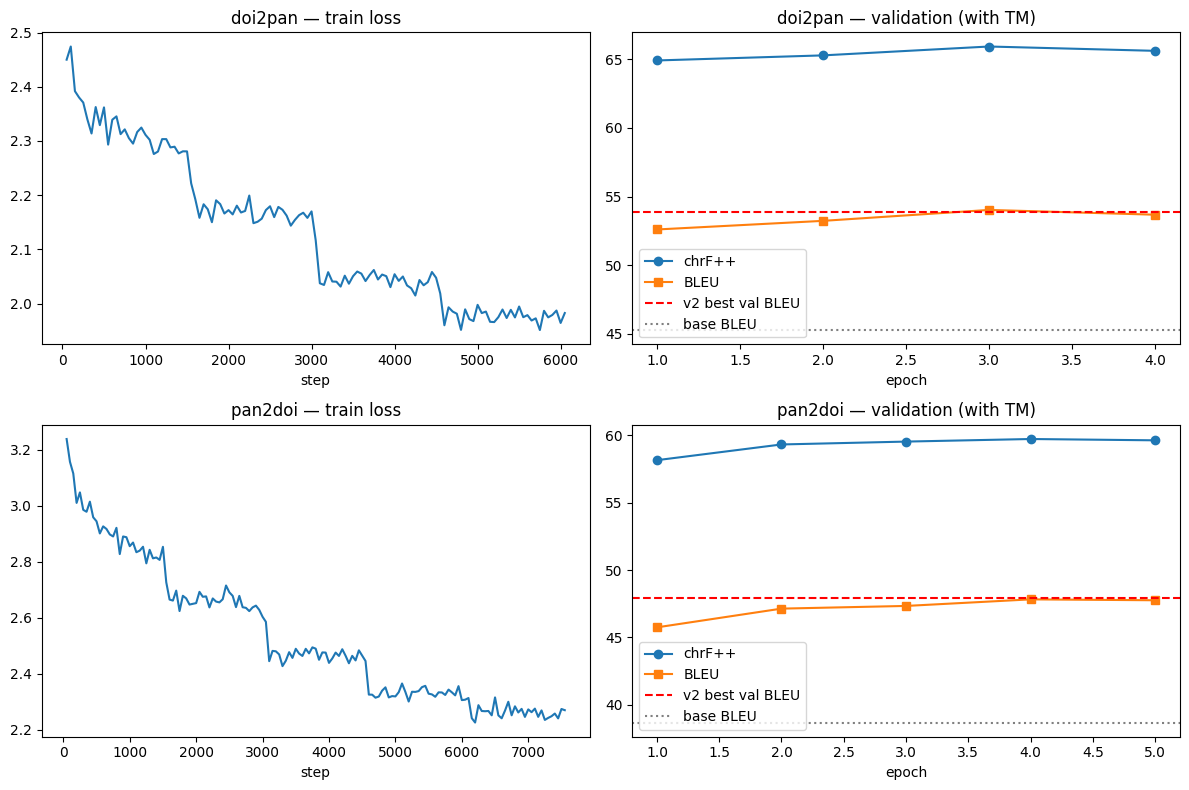

In [12]:
# =============================================================================
# CELL 12 — TRAINING / VALIDATION CURVES   (v2 val BLEU at best epoch for reference: doi2pan 53.89, pan2doi 47.89)
# =============================================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(DIRECTIONS), 2, figsize=(12, 4 * len(DIRECTIONS)))
V2_VAL_BLEU = {"doi2pan": 53.89, "pan2doi": 47.89}
for r, d in enumerate(DIRECTIONS):
    out_dir = RESULT[d]["out_dir"]
    logs = json.load(open(os.path.join(out_dir, "log_history.json")))
    tr = [(l["step"], l["loss"]) for l in logs if "loss" in l]
    if tr:
        axes[r][0].plot(*zip(*tr)); axes[r][0].set_title(f"{d} — train loss"); axes[r][0].set_xlabel("step")
    vh = json.load(open(os.path.join(out_dir, "val_history.json")))
    axes[r][1].plot([v["epoch"] for v in vh], [v["chrf"] for v in vh], marker="o", label="chrF++")
    axes[r][1].plot([v["epoch"] for v in vh], [v["bleu"] for v in vh], marker="s", label="BLEU")
    axes[r][1].axhline(V2_VAL_BLEU[d], ls="--", c="red", label="v2 best val BLEU")
    axes[r][1].axhline(BASE_VAL[d]["bleu"], ls=":", c="gray", label="base BLEU")
    axes[r][1].set_title(f"{d} — validation (with TM)"); axes[r][1].set_xlabel("epoch"); axes[r][1].legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "training_curves.png", dpi=120); plt.show()


In [13]:
# =============================================================================
# CELL 13 — FINAL TEST  (the ONLY time the test set is used)
#   same adapter evaluated twice: WITH the translation memory and WITHOUT (ablation), beam 5 / lp 1.0 for both.
# =============================================================================
def paired_bootstrap(a, b, refs, n=300, seed=SEED):
    """BLEU(a) - BLEU(b) over bootstrap resamples of the test sentences -> (mean, (lo, hi), P[a > b])."""
    rng = np.random.RandomState(seed)
    a, b, refs = np.array(a, dtype=object), np.array(b, dtype=object), np.array(refs, dtype=object)
    N, diffs = len(refs), []
    for _ in range(n):
        ix = rng.randint(0, N, N)
        r = [refs[ix].tolist()]
        diffs.append(sacrebleu.corpus_bleu(a[ix].tolist(), r, tokenize=BLEU_TOKENIZE).score
                     - sacrebleu.corpus_bleu(b[ix].tolist(), r, tokenize=BLEU_TOKENIZE).score)
    diffs = np.array(diffs)
    return diffs.mean(), tuple(np.percentile(diffs, [2.5, 97.5])), float((diffs > 0).mean())

rows, TEST_PREDS, BUCKET_ROWS = [], {}, []
for d in DIRECTIONS:
    info = direction_data[d]
    te = info["test"]
    srcs, refs = te["src_text"].tolist(), te["tgt_text"].tolist()
    m = load_with_adapter(RESULT[d]["best_dir"])

    p_tm = translate(m, srcs, info["src_lang"], info["tgt_lang"], num_beams=TEST_BEAMS,
                     length_penalty=TEST_LENGTH_PENALTY, suffixes=te["tm_suffix"].tolist())
    p_no = translate(m, srcs, info["src_lang"], info["tgt_lang"], num_beams=TEST_BEAMS,
                     length_penalty=TEST_LENGTH_PENALTY, suffixes=None)
    TEST_PREDS[d] = {"tm": p_tm, "no_tm": p_no}
    rows.append({"direction": d, "system": "v3 adapter + TM", "N": len(refs), **score_full(p_tm, refs)})
    rows.append({"direction": d, "system": "v3 adapter, TM switched off", "N": len(refs), **score_full(p_no, refs)})
    rows.append({"direction": d, "system": "v2 (reported)", "N": len(refs), **V2_TEST[d]})
    rows.append({"direction": d, "system": "Base IndicTrans2-1B (reported)", "N": len(refs), **BASE_TEST[d]})

    pd.DataFrame({"src": srcs, "ref": refs, "pred_tm": p_tm, "pred_no_tm": p_no, "tm_score": te["tm_score"],
                  "tm_tgt": te["tm_tgt_raw"]}).to_csv(RESULTS_DIR / f"{d}_test_predictions.csv", index=False)

    sc = te["tm_score"].values
    for lo, hi in BUCKETS:
        mk = (sc >= lo) & (sc < hi)
        if mk.sum() < 5:
            continue
        r_ = [x for x, k in zip(refs, mk) if k]
        BUCKET_ROWS.append({"direction": d, "match score": bucket_name(lo, hi), "n": int(mk.sum()),
                            "BLEU +TM": sacrebleu.corpus_bleu([x for x, k in zip(p_tm, mk) if k], [r_], tokenize=BLEU_TOKENIZE).score,
                            "BLEU no TM": sacrebleu.corpus_bleu([x for x, k in zip(p_no, mk) if k], [r_], tokenize=BLEU_TOKENIZE).score})

    shutil.copytree(RESULT[d]["best_dir"], FINAL_DIR / d, dirs_exist_ok=True)
    pd.DataFrame({"src": TM_MEM_TEST[d]["src"], "tgt": TM_MEM_TEST[d]["tgt_raw"]}).to_csv(FINAL_DIR / d / "tm_memory.csv", index=False)
    json.dump({"decoding": {"num_beams": TEST_BEAMS, "length_penalty": TEST_LENGTH_PENALTY}, "hp": HP[d],
               "tm": {"use": USE_TM, "min_score": TM_MIN_SCORE, "include_src": TM_INCLUDE_SRC, "sep": TM_SEP}},
              open(FINAL_DIR / d / "run_info.json", "w"), indent=2)
    del m; gc.collect(); torch.cuda.empty_cache()

final_df = pd.DataFrame(rows)
final_df.to_csv(RESULTS_DIR / "FINAL_dogpun_test_results_v3.csv", index=False)
print("=" * 90 + "\nFINAL TEST RESULTS v3 — DOGRI <-> PUNJABI (independent adapters)\n" + "=" * 90)
display(final_df.round(3))

print("\nTM effect and significance (paired bootstrap, 300 resamples, BLEU):")
for d in DIRECTIONS:
    refs = direction_data[d]["test"]["tgt_text"].tolist()
    f = final_df[(final_df.direction == d) & (final_df.system == "v3 adapter + TM")].iloc[0]
    n = final_df[(final_df.direction == d) & (final_df.system == "v3 adapter, TM switched off")].iloc[0]
    mean, ci, pwin = paired_bootstrap(TEST_PREDS[d]["tm"], TEST_PREDS[d]["no_tm"], refs)
    print(f"  {d}: BLEU {f['BLEU']:.2f} (TM off {n['BLEU']:.2f}, v2 {V2_TEST[d]['BLEU']:.2f}, base {BASE_TEST[d]['BLEU']:.2f}) | "
          f"TM gain {mean:+.2f} [95% CI {ci[0]:+.2f}, {ci[1]:+.2f}], P(TM better)={pwin:.2f} | chrF++ {f['chrF++']:.2f} (v2 {V2_TEST[d]['chrF++']:.2f})")

print("\nBLEU by match-quality bucket (where does the gain come from?):")
display(pd.DataFrame(BUCKET_ROWS).round(2))
print("\nAdapters + tm_memory.csv per direction:", FINAL_DIR)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


doi->pan:   0%|          | 0/73 [00:00<?, ?it/s]

doi->pan:   0%|          | 0/73 [00:00<?, ?it/s]

pan->doi:   0%|          | 0/73 [00:00<?, ?it/s]

pan->doi:   0%|          | 0/73 [00:00<?, ?it/s]

FINAL TEST RESULTS v3 — DOGRI <-> PUNJABI (independent adapters)


,direction,system,N,BLEU,chrF++,BP,len_ratio
0,doi2pan,v3 adapter + TM,1158,53.257,65.486,0.990,0.990
1,doi2pan,"v3 adapter, TM switched off",1158,53.207,65.452,0.990,0.990
2,doi2pan,v2 (reported),1158,53.262,65.414,NaN,NaN
3,doi2pan,Base IndicTrans2-1B (reported),1158,45.311,58.722,NaN,NaN
4,pan2doi,v3 adapter + TM,1158,46.747,58.873,0.988,0.988
5,pan2doi,"v3 adapter, TM switched off",1158,46.618,58.782,0.987,0.987
6,pan2doi,v2 (reported),1158,46.702,58.847,NaN,NaN
7,pan2doi,Base IndicTrans2-1B (reported),1158,38.824,52.653,NaN,NaN



TM effect and significance (paired bootstrap, 300 resamples, BLEU):
  doi2pan: BLEU 53.26 (TM off 53.21, v2 53.26, base 45.31) | TM gain +0.05 [95% CI -0.06, +0.17], P(TM better)=0.80 | chrF++ 65.49 (v2 65.41)
  pan2doi: BLEU 46.75 (TM off 46.62, v2 46.70, base 38.82) | TM gain +0.13 [95% CI +0.00, +0.26], P(TM better)=0.98 | chrF++ 58.87 (v2 58.85)

BLEU by match-quality bucket (where does the gain come from?):


,direction,match score,n,BLEU +TM,BLEU no TM
0,doi2pan,"[0.0,0.4)",998,52.63,52.63
1,doi2pan,"[0.4,0.6)",143,58.06,57.79
2,doi2pan,"[0.6,0.8)",17,61.15,58.94
3,pan2doi,"[0.0,0.4)",956,46.10,46.09
4,pan2doi,"[0.4,0.6)",178,51.32,50.82
5,pan2doi,"[0.6,0.8)",19,44.72,41.68
6,pan2doi,"[0.8,1.0]",5,38.99,39.11



Adapters + tm_memory.csv per direction: /kaggle/working/dogpun_indictrans2_v3/final_adapters


In [14]:
# =============================================================================
# CELL 14 — ERROR ANALYSIS of the final predictions (what is still wrong?)
#   * word confusions  : most frequent (predicted -> reference) single-word substitutions
#   * orthographic share: how many substitutions vanish once nukta / virama / anusvara / avagraha / ZWJ are ignored
#     (high share => the references themselves are spelled inconsistently -> a hard BLEU ceiling that no model can beat)
#   * BLEU by source length
# =============================================================================
from collections import Counter

DIAC_RE = re.compile("[\u093c\u094d\u0902\u0901\u093d\u0a3c\u0a4d\u0a02\u0a70\u0a71\u200c\u200d]")

def word_confusions(preds, refs):
    c = Counter()
    for p, r in zip(preds, refs):
        pw, rw = p.split(), r.split()
        for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, pw, rw, autojunk=False).get_opcodes():
            if tag == "replace" and (i2 - i1) == (j2 - j1):
                for a, b in zip(pw[i1:i2], rw[j1:j2]):
                    c[(a, b)] += 1
    return c

for d in DIRECTIONS:
    te = direction_data[d]["test"]
    refs, preds = te["tgt_text"].tolist(), TEST_PREDS[d]["tm"]
    c = word_confusions(preds, refs)
    total = sum(c.values())
    orth = sum(v for (a, b), v in c.items() if DIAC_RE.sub("", a) == DIAC_RE.sub("", b))
    print(f"\n=== {d} === single-word substitutions: {total:,} | differ only by diacritic/virama/nukta: {orth / max(total, 1):.1%}")
    print("  most frequent (predicted -> reference):")
    for (a, b), v in c.most_common(20):
        print(f"    {v:3d}x  {a}  ->  {b}")
    L = np.array([len(s.split()) for s in te["src_text"]])
    qs = np.percentile(L, [0, 33, 66, 100])
    for lo, hi in zip(qs[:-1], qs[1:]):
        mk = (L >= lo) & (L <= hi)
        r_ = [x for x, k in zip(refs, mk) if k]
        b_ = sacrebleu.corpus_bleu([x for x, k in zip(preds, mk) if k], [r_], tokenize=BLEU_TOKENIZE).score
        print(f"  source length {int(lo):3d}-{int(hi):3d} words: n={int(mk.sum()):4d}  BLEU={b_:.2f}")



=== doi2pan === single-word substitutions: 2,854 | differ only by diacritic/virama/nukta: 4.6%
  most frequent (predicted -> reference):
     20x  ਵਿੱਚ  ->  ਵਿਚ
     19x  ਦੇ  ->  ਦਾ
     19x  ਹੈ।  ->  ਹਨ।
     18x  ਇਨ੍ਹਾਂ  ->  ਇਹਨਾਂ
     14x  ਹਨ।  ->  ਹੈ।
     14x  ਦੀ  ->  ਦੇ
     13x  ਉਨ੍ਹਾਂ  ->  ਉਹਨਾਂ
     13x  ਦੀ  ->  ਦਾ
     11x  ਕਰੋਡ਼  ->  ਕਰੋੜ
     10x  ਦੇ  ->  ਦੀ
     10x  ਹਨ,  ->  ਹਨ
      9x  ਹੈ,  ->  ਹੈ
      9x  ਨੂੰ  ->  ਦੀ
      8x  ਵਿੱਚ  ->  ਦੇ
      7x  ਦੀ  ->  ਦੀਆਂ
      7x  ਵਿੱਚ  ->  'ਤੇ
      7x  ਹੈ  ->  ਹੈ,
      7x  ਨੂੰ  ->  ਦੇ
      7x  ਦਾ  ->  ਦੇ
      6x  ਰੂਪ  ->  ਤੌਰ
  source length   2- 15 words: n= 388  BLEU=56.51
  source length  15- 23 words: n= 461  BLEU=54.08
  source length  23- 43 words: n= 404  BLEU=51.80

=== pan2doi === single-word substitutions: 3,733 | differ only by diacritic/virama/nukta: 5.5%
  most frequent (predicted -> reference):
     28x  आह्ले  ->  आह्‌ले
     19x  आस्तै  ->  लेई
     16x  ऐ।  ->  न।
     15x  दी  ->  दे
     14x  न।  ->  ऐ